# P0 · The 45-minute skeleton (memorize this order)

**ID:** P0 · **Target:** 45 min · **Plan week:** 1 (Saturday: write it from memory), 6, 9 and 16 (full mock runs on unseen datasets) · **Part:** P (PyTorch first principles)

**The drill.** This is the "blank Colab" interview in its full form. Build a 10-class classifier on
scikit-learn's bundled `load_digits` (1797 8×8 grey images, pixel values 0-16, offline) by writing the
**eight steps of guide §P0 in order**, one cell per step, talking out loud the whole time:

1. Data: load, inspect shapes/dtypes/class balance, stratified train/val/test split, normalize with train statistics only.
2. `Dataset` / `DataLoader` (shuffle train only, sensible batch size, `collate_fn` if lengths vary).
3. Model as an `nn.Module`; output raw logits; count parameters.
4. Loss chosen from the task (P1 table), optimizer (AdamW default) and LR.
5. Training loop: `model.train()`, to device, forward, loss, `zero_grad`, `backward`, (clip), `step`; log the loss.
6. Eval loop: `model.eval()` + `torch.no_grad()`, metrics aggregated over the whole set.
7. Sanity checks: initial loss vs ln C, overfit one batch, read the curves for over/underfitting.
8. Improve and discuss: regularization, LR schedule, early stopping, checkpointing, error analysis.

The sanity checks (step 7) run **before** the long training run: they are cheap and catch most bugs.
After the skeleton there is a short **loss-selection quiz** (guide §P1) and a list of **unseen datasets for the
week-6 mock runs**.

**Rules.** No docs, no LLM. Each solution cell keeps only its spec (comments). The self-check cell names
the variables it expects. Then answer the questions out loud and log the session.

## Sources
- PyTorch tutorial, *Learn the Basics* (Datasets & DataLoaders, Build the Model, Optimization loop):
  https://docs.pytorch.org/tutorials/beginner/basics/intro.html (BSD-3; skeleton order follows its train/test loops).
- PyTorch tutorial, *Saving and Loading Models* (state_dict, general checkpoint with optimizer):
  https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html
- A. Karpathy, *A Recipe for Training Neural Networks* (2019): "verify loss @ init", "overfit one batch",
  "visualize prediction dynamics": https://karpathy.github.io/2019/04/25/recipe/
- V. Godbole, G. Dahl, J. Gilmer, C. Shallue, Z. Nado, *Deep Learning Tuning Playbook* (2023),
  "Saving checkpoints and retrospectively selecting the best checkpoint":
  https://github.com/google-research/tuning_playbook (commit 7554a51, `README.md`, CC-BY-4.0).
- I. Loshchilov, F. Hutter, *Decoupled Weight Decay Regularization* (AdamW), ICLR 2019, arXiv:1711.05101 —
  https://arxiv.org/abs/1711.05101
- I. Loshchilov, F. Hutter, *SGDR: Stochastic Gradient Descent with Warm Restarts* (cosine schedule), ICLR 2017,
  arXiv:1608.03983 — https://arxiv.org/abs/1608.03983
- scikit-learn `load_digits` (copy of the UCI "Optical Recognition of Handwritten Digits" test set):
  https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html ·
  https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits
- `torch.nn.CrossEntropyLoss` docs (class-index `long` targets, `label_smoothing`, `ignore_index`):
  https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html

In [1]:
import copy
import math
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

from prep import Session, check, check_close, seed_everything

s = Session("P0", target_min=45)
seed_everything(0)
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

[P0] started 12:41; target 45 min


In [2]:
# 1. DATA. X, y = sklearn.datasets.load_digits(return_X_y=True). Print shapes, dtypes, value range, class counts.
#    Stratified split 70/15/15 with train_test_split(..., stratify=..., random_state=0) twice
#    -> X_train, X_val, X_test, y_train, y_val, y_test (numpy).
#    Standardize per feature with TRAIN mean/std only -> `mu`, `sd`. Some pixels are always 0 in train:
#    guard the std (e.g. sd[sd < 1e-6] = 1) so nothing becomes NaN.
#    Convert X to float32 tensors, y to int64 (long) tensors.
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

X, y = load_digits(return_X_y=True)
print(X.shape, X.dtype, y.shape, y.dtype, "range", X.min(), X.max())
print("class counts", np.bincount(y))
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=0)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=0)
mu, sd = X_train.mean(0), X_train.std(0)
print("constant pixels in train:", int((sd < 1e-6).sum()))
sd[sd < 1e-6] = 1.0  # constant feature: (x - mu) is 0 anyway, avoid 0/0
X_train, X_val, X_test = (torch.tensor((a - mu) / sd, dtype=torch.float32) for a in (X_train, X_val, X_test))
y_train, y_val, y_test = (torch.tensor(a, dtype=torch.long) for a in (y_train, y_val, y_test))
print(X_train.shape, X_val.shape, X_test.shape)

(1797, 64) float64 (1797,) int64 range 0.0 16.0
class counts [178 182 177 183 181 182 181 179 174 180]
constant pixels in train: 4
torch.Size([1257, 64]) torch.Size([270, 64]) torch.Size([270, 64])


In [3]:
# 2. DATASET / DATALOADER. Write a map-style `Dataset` subclass `ArrayDataset(X, y)` with __len__ and
#    __getitem__ returning (x_i, y_i). Build train_ds/val_ds/test_ds and DataLoaders:
#    train_dl (batch 64, shuffle=True), val_dl and test_dl (batch 512, shuffle=False).
#    (No collate_fn needed: every example has the same shape. Say when you WOULD need one.)
class ArrayDataset(Dataset):
    def __init__(self, X, y):
        assert len(X) == len(y)
        self.X, self.y = X, y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        return self.X[i], self.y[i]


train_ds, val_ds, test_ds = ArrayDataset(X_train, y_train), ArrayDataset(X_val, y_val), ArrayDataset(X_test, y_test)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=512)
test_dl = DataLoader(test_ds, batch_size=512)
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb.shape, yb.dtype)

torch.Size([64, 64]) torch.float32 torch.Size([64]) torch.int64


In [4]:
# 3. MODEL. `class MLP(nn.Module)`: 64 -> 128 -> 128 -> 10, ReLU, Dropout(p=0.1) after each hidden layer.
#    forward returns RAW LOGITS of shape (B, 10) (no softmax). `make_model()` returns a fresh one on `dev`.
#    `model = make_model()`; print the parameter count.
class MLP(nn.Module):
    def __init__(self, d_in=64, d_h=128, n_out=10, p=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, d_h), nn.ReLU(), nn.Dropout(p),
            nn.Linear(d_h, d_h), nn.ReLU(), nn.Dropout(p),
            nn.Linear(d_h, n_out),
        )

    def forward(self, x):
        return self.net(x)


def make_model():
    return MLP().to(dev)


model = make_model()
print(sum(p.numel() for p in model.parameters()), "params")  # 64*128+128 + 128*128+128 + 128*10+10 = 26122

26122 params


In [5]:
# 4. LOSS + OPTIMIZER. `loss_fn = nn.CrossEntropyLoss()` (targets: long class indices, shape (B,)).
#    `opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)`.
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

In [6]:
# 5. TRAIN LOOP. `train_one_epoch(model, dl, opt, clip=1.0) -> mean train loss` (weighted by batch size).
#    model.train(); per batch: to(dev), forward, loss, opt.zero_grad(), loss.backward(),
#    torch.nn.utils.clip_grad_norm_(model.parameters(), clip), opt.step().
def train_one_epoch(model, dl, opt, clip=1.0):
    model.train()
    tot, n = 0.0, 0
    for xb, yb in dl:
        xb, yb = xb.to(dev), yb.to(dev)
        loss = loss_fn(model(xb), yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()
        tot += loss.item() * len(yb)
        n += len(yb)
    return tot / n

In [7]:
# 6. EVAL LOOP. `evaluate(model, dl) -> (mean loss, accuracy)` over the WHOLE set:
#    model.eval() + torch.no_grad(); sum loss * batch size and correct counts, divide by N at the end.
#    Also `predict(model, dl) -> (all_logits, all_targets)` concatenated on CPU, for error analysis.
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    tot, correct, n = 0.0, 0, 0
    for xb, yb in dl:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = model(xb)
        tot += loss_fn(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(yb)
    return tot / n, correct / n


@torch.no_grad()
def predict(model, dl):
    model.eval()
    out, ys = [], []
    for xb, yb in dl:
        out.append(model(xb.to(dev)).cpu())
        ys.append(yb)
    return torch.cat(out), torch.cat(ys)

init loss 2.300 vs ln10 = 2.303


overfit-one-batch loss 0.0000


epoch 10 train 0.059 val 0.092 acc 0.978


epoch 20 train 0.015 val 0.070 acc 0.970


epoch 30 train 0.007 val 0.062 acc 0.970


epoch 40 train 0.005 val 0.093 acc 0.974


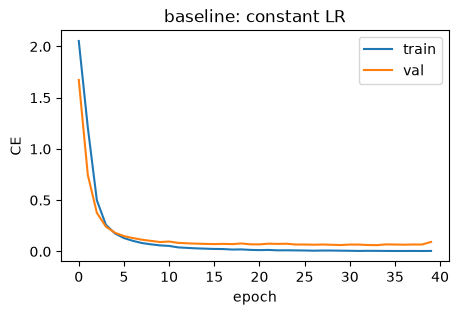

In [8]:
# 7. SANITY CHECKS (before the long run), then a plain baseline run.
#    (a) `init_loss`, _ = evaluate(model, val_dl); compare with ln 10.
#    (b) Overfit ONE batch of 32 train examples with a fresh model, AdamW lr=1e-2, 300 steps
#        (no dropout effect matters: call .eval() OR keep train mode, your choice; say why). Store `overfit_loss`.
#    (c) Baseline: train `model` for 40 epochs with constant LR; record `history` dict with
#        "train_loss", "val_loss", "val_acc" per epoch. Plot train vs val loss and say what you see.
init_loss, _ = evaluate(model, val_dl)
print(f"init loss {init_loss:.3f} vs ln10 = {math.log(10):.3f}")

tmp = make_model().eval()  # eval(): turn dropout off so the check isolates the optimisation
tmp_opt = torch.optim.AdamW(tmp.parameters(), lr=1e-2)
xb, yb = X_train[:32].to(dev), y_train[:32].to(dev)
for _ in range(300):
    loss = loss_fn(tmp(xb), yb)
    tmp_opt.zero_grad()
    loss.backward()
    tmp_opt.step()
overfit_loss = loss.item()
print(f"overfit-one-batch loss {overfit_loss:.4f}")

history = {"train_loss": [], "val_loss": [], "val_acc": []}
for epoch in range(40):
    tl = train_one_epoch(model, train_dl, opt)
    vl, va = evaluate(model, val_dl)
    for k, v in zip(history, (tl, vl, va)):
        history[k].append(v)
    if epoch % 10 == 9:
        print(f"epoch {epoch + 1:2d} train {tl:.3f} val {vl:.3f} acc {va:.3f}")
plt.figure(figsize=(5, 3))
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("CE"); plt.legend(); plt.title("baseline: constant LR")
plt.show()

best epoch 25, best val loss 0.0979 (baseline min 0.0615), stopped at 45
one val example = 0.37% accuracy: do not over-read small differences
test loss 0.070 acc 0.9815
most frequent (true, pred) mistakes: [((9, 5), 1), ((4, 8), 1), ((6, 1), 1)]


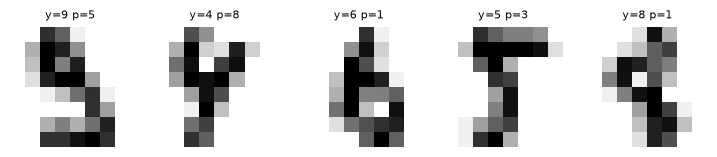

In [9]:
# 8. IMPROVE + DISCUSS. Fresh model `best_model` trained with:
#    - AdamW lr=1e-3, wd=5e-2, CosineAnnealingLR over max 60 epochs (scheduler.step() once per EPOCH);
#      record the LR each epoch in a list `lrs`;
#    - early stopping on val LOSS with patience 20: keep a deep copy of the best state_dict,
#      store `best_val_loss`, `best_epoch`, `stopped_epoch`;
#    - checkpoint the best {model, optimizer, epoch} with torch.save to `ckpt_path` inside tempfile.mkdtemp();
#      after training, load it back into a FRESH model -> `best_model`.
#    Then touch the test set ONCE: `test_loss, test_acc = evaluate(best_model, test_dl)`.
#    Error analysis: confusion pairs on test (`pairs`: the 3 most frequent (true, pred) mistakes) and a plot of
#    a few misclassified test images (un-standardize with mu/sd, reshape to 8x8).
model2 = make_model()
opt2 = torch.optim.AdamW(model2.parameters(), lr=1e-3, weight_decay=5e-2)
max_epochs, patience = 60, 20
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=max_epochs)
ckpt_path = os.path.join(tempfile.mkdtemp(), "best.pt")
best_val_loss, best_epoch, bad, lrs = float("inf"), -1, 0, []
for epoch in range(max_epochs):
    lrs.append(opt2.param_groups[0]["lr"])
    train_one_epoch(model2, train_dl, opt2)
    sched.step()
    vl, va = evaluate(model2, val_dl)
    if vl < best_val_loss:
        best_val_loss, best_epoch, bad = vl, epoch, 0
        torch.save({"model": copy.deepcopy(model2.state_dict()), "opt": opt2.state_dict(), "epoch": epoch}, ckpt_path)
    else:
        bad += 1
        if bad >= patience:
            break
stopped_epoch = epoch
print(f"best epoch {best_epoch}, best val loss {best_val_loss:.4f} (baseline min {min(history['val_loss']):.4f}), stopped at {stopped_epoch}")
print(f"one val example = {1 / len(val_ds):.2%} accuracy: do not over-read small differences")

ckpt = torch.load(ckpt_path, map_location=dev)
best_model = make_model()
best_model.load_state_dict(ckpt["model"])
test_loss, test_acc = evaluate(best_model, test_dl)
print(f"test loss {test_loss:.3f} acc {test_acc:.4f}")

logits, ys = predict(best_model, test_dl)
pred = logits.argmax(1)
wrong = (pred != ys).nonzero().squeeze(1)
pair_counts = {}
for t, p in zip(ys[wrong].tolist(), pred[wrong].tolist()):
    pair_counts[(t, p)] = pair_counts.get((t, p), 0) + 1
pairs = sorted(pair_counts, key=pair_counts.get, reverse=True)[:3]
print("most frequent (true, pred) mistakes:", [(p, pair_counts[p]) for p in pairs])
fig, axes = plt.subplots(1, min(6, len(wrong)), figsize=(9, 1.8), squeeze=False)
for ax, i in zip(axes[0], wrong[:6].tolist()):
    ax.imshow((X_test[i].numpy() * sd + mu).reshape(8, 8), cmap="gray_r")
    ax.set_title(f"y={ys[i].item()} p={pred[i].item()}", fontsize=8)
    ax.axis("off")
plt.show()

## Self-check
Expects: `mu`, `sd`, `X_train`, `y_train`, `train_ds`, `model`, `make_model`, `init_loss`, `overfit_loss`,
`history`, `lrs`, `best_model`, `best_val_loss`, `ckpt_path`, `stopped_epoch`, `test_acc`, `evaluate`, `val_dl`.

In [10]:
check("no NaN after standardization", not torch.isnan(X_train).any().item(), "guard the zero-std pixels")
check_close("train mean ~ 0 (train stats used)", X_train.mean(0), torch.zeros(X_train.shape[1]), atol=1e-4)
check("targets are long class indices", y_train.dtype == torch.long and y_train.ndim == 1, f"got {y_train.dtype}, shape {tuple(y_train.shape)}")
check("Dataset length/item", len(train_ds) == len(X_train) and len(train_ds[0]) == 2)
check("model outputs (B, 10) logits", model(X_train[:7].to(dev)).shape == (7, 10))
check("no Softmax layer in the model", not any(isinstance(m, (nn.Softmax, nn.LogSoftmax)) for m in model.modules()))
check("initial loss ~ ln 10", abs(init_loss - math.log(10)) < 0.3, f"got {init_loss:.3f}")
check("can overfit one batch", overfit_loss < 0.05, f"got {overfit_loss:.4f}")
check("history has one entry per epoch", len(history["train_loss"]) == len(history["val_loss"]) == len(history["val_acc"]) > 0)
check("LR schedule actually decays", len(lrs) > 1 and lrs[-1] < lrs[0], f"lrs[0]={lrs[0]:.2e}, lrs[-1]={lrs[-1]:.2e}")
reloaded = make_model()
reloaded.load_state_dict(torch.load(ckpt_path, map_location=dev)["model"])
check_close("checkpoint reproduces best val loss", evaluate(reloaded, val_dl)[0], best_val_loss, atol=1e-5)
check("checkpoint also stores the optimizer state", "opt" in torch.load(ckpt_path, map_location=dev) or "optimizer" in torch.load(ckpt_path, map_location=dev))
check("eval is deterministic (dropout off in eval)", evaluate(best_model, val_dl) == evaluate(best_model, val_dl))
check("test accuracy > 0.93", test_acc > 0.93, f"got {test_acc:.3f}")

ok  no NaN after standardization
ok  train mean ~ 0 (train stats used)
ok  targets are long class indices
ok  Dataset length/item
ok  model outputs (B, 10) logits
ok  no Softmax layer in the model
ok  initial loss ~ ln 10
ok  can overfit one batch
ok  history has one entry per epoch
ok  LR schedule actually decays
ok  checkpoint reproduces best val loss
ok  checkpoint also stores the optimizer state
ok  eval is deterministic (dropout off in eval)
ok  test accuracy > 0.93


## Loss-selection quiz (guide §P1)
For each task say, in one breath: **model output shape, loss (PyTorch class), target dtype + shape**, and the trap.
1. Spam vs not spam, one score per email.
2. ImageNet classification, 1000 classes, one label per image.
3. Tag a photo with any subset of 20 attributes.
4. Next-token prediction for a GPT, batch B, length T, vocab V, right-padded sequences.
5. Semantic segmentation into C classes on H×W images.
6. Predict house price; also predict an uncertainty for it.
7. Predict number of clicks per hour.
8. Distil a teacher's softmax distribution into a student.
9. Train image/text embeddings so matching pairs are close.
10. 0.1% fraud transactions; the model keeps predicting "not fraud".

<details><summary>Quiz answers</summary>

| # | Output | Loss | Target | Trap |
| --- | --- | --- | --- | --- |
| 1 | (N,) one logit | `nn.BCEWithLogitsLoss` | float 0/1, (N,) | no sigmoid in the model; (N,1) vs (N,) |
| 2 | (N, 1000) logits | `nn.CrossEntropyLoss` | long indices, (N,) | never softmax first; not one-hot floats unless you mean soft labels |
| 3 | (N, 20) logits | `nn.BCEWithLogitsLoss` (per class) | float 0/1 matrix, (N, 20) | threshold per class at eval; not CE (labels aren't exclusive) |
| 4 | (B, T, V) logits | `F.cross_entropy(logits.view(-1, V), y.view(-1), ignore_index=-100)` | long, (B·T,), shifted by one, pads = -100 | forgetting the shift or the pad mask; reshape vs transpose |
| 5 | (N, C, H, W) | `nn.CrossEntropyLoss` (+ Dice) | long, (N, H, W) | target shape; class imbalance (weights / Dice) |
| 6 | mean (N,) + variance (N,) | `nn.GaussianNLLLoss` (MSE if no uncertainty) | float (N,) | variance must stay positive (softplus); standardize targets |
| 7 | (N,) log-rate | `nn.PoissonNLLLoss(log_input=True)` | float counts (N,) | predicting the rate directly can go negative |
| 8 | (N, C) log-probs | `nn.KLDivLoss(reduction="batchmean")` | probs (N, C) | input must be log-probs; `"mean"` divides by N·C; KL direction |
| 9 | (N, d) embeddings | InfoNCE = `F.cross_entropy(sim / τ, arange(N))` | long arange | L2-normalize; temperature |
| 10 | (N,) logit | BCE with `pos_weight` (≈ n_neg/n_pos) or focal loss | float 0/1 | accuracy is meaningless; tune the threshold; report PR-AUC |
</details>

## Unseen datasets for mock runs (weeks 6, 10, 16)
Pick one you have not used for a while, start a 45-minute timer, and run the eight steps from a blank notebook.
All load offline (sklearn bundles the small ones; the rest are in `prep.DATA`).

| Dataset | Task | One-line loader |
| --- | --- | --- |
| Breast cancer (569×30) | binary, mild imbalance | `X, y = sklearn.datasets.load_breast_cancer(return_X_y=True)` |
| Wine (178×13) | 3-class, tiny: use k-fold | `X, y = sklearn.datasets.load_wine(return_X_y=True)` |
| Digits as regression | regress the digit value 0-9 (MSE vs Huber) | `X, y = sklearn.datasets.load_digits(return_X_y=True); y = y.astype("float32")` |
| Diabetes (442×10) | regression, small and noisy | `X, y = sklearn.datasets.load_diabetes(return_X_y=True)` |
| California housing (20640×8) | regression, capped target | `sklearn.datasets.fetch_california_housing(data_home=DATA/"sklearn", download_if_missing=False)` |
| FashionMNIST | 10-class images | `torchvision.datasets.FashionMNIST(DATA, train=True, download=False)` |
| MNIST | 10-class images (or a VAE) | `torchvision.datasets.MNIST(DATA, train=True, download=False)` |
| AG News subset | 4-class text | `pd.read_parquet(DATA/"ag_news"/"train.parquet").sample(20000, random_state=0)` |
| Synthetic multilabel | 5-10 labels per row | `sklearn.datasets.make_multilabel_classification(n_samples=5000, n_classes=8, random_state=0)` |
| Synthetic 1 % positives | imbalanced binary | `sklearn.datasets.make_classification(n_samples=50000, weights=[0.99], random_state=0)` |

## Say it out loud (P3)
1. Walk through the eight steps in order without notes. Which one would you skip under time pressure, and which never?
2. Why is the initial loss ln 10 here, and what would an initial loss of 5 tell you?
3. Why did the overfit-one-batch check turn dropout off? What does it mean if you cannot overfit 32 examples?
4. What do `model.train()` / `model.eval()` change in *this* model, and what does `torch.no_grad()` save?
5. AdamW vs Adam with L2 regularization: what is the difference? Why AdamW as the default, and what LR would you start at?
6. Read the baseline curves: is it over- or underfitting? What would you try first, and why?
7. Early stopping with a cosine schedule: what is subtle about stopping early when the schedule assumes a fixed length?
8. What goes in a checkpoint if you want to *resume* training, not just evaluate?
9. When do you need a `collate_fn`?

<details><summary>Model answers</summary>

1. Data → Dataset/DataLoader → model → loss+opt → train loop → eval loop → sanity checks → improve. Under time pressure
   cut step 8 to one improvement plus discussion. Never skip the initial-loss and overfit-one-batch checks: they take
   under a minute and catch most bugs (Karpathy's recipe).
2. With near-zero logits the softmax is uniform: the loss is −log(1/10) = ln 10 ≈ 2.303. An initial loss of 5 means the
   model is confidently wrong at init. The usual causes are a final layer scaled too large, inputs that are not
   normalized, or a label/logit mismatch. Fix the init (scale the last layer down, set the bias to log class priors)
   before you tune anything.
3. Dropout adds noise, so the loss on a fixed batch cannot reach ~0. Turning it off isolates the question "can the
   optimiser + model + loss fit these labels at all?". If they can't fit 32 examples, there is a bug: labels don't
   match the inputs, the LR is wrong, gradients are detached, `zero_grad` is missing, or a softmax was applied before CE.
4. Dropout is active in train and an identity in eval (PyTorch scales the kept units by 1/(1−p) during training).
   With BatchNorm, eval would also switch to running statistics. `no_grad` doesn't record the autograd graph, so
   activations are not kept for backward. That saves memory and time.
5. Adam with an L2 term adds λw to the gradient, so the decay gets divided by √v̂ and weights with large gradients
   are decayed less. AdamW applies the decay directly to the weights (w ← w − ηλw), decoupled from the adaptive
   scaling (Loshchilov & Hutter, arXiv:1711.05101). Start at about 1e-3 for small MLPs. 3e-4 is the common
   transformer default. Then sweep by factors of about 3.
6. With 1257 training examples, the train loss keeps falling while the val loss flattens and then rises slowly:
   that is mild overfitting. Try more weight decay or dropout, a decaying LR, or early stopping on val loss.
   Get more data (augmentation) if you can. Also, with 270 val examples one example is worth 0.37 % accuracy, so
   differences between runs are mostly noise. Compare several seeds, or use k-fold, before claiming an improvement.
7. Cosine annealing gets a lot of its gain at the end, when the LR is small. If you stop at epoch 20 of 60, the LR
   is still high, so you are comparing an unfinished schedule. Common fixes: choose the budget first and keep the
   best checkpoint (retrospective selection, as the tuning playbook recommends), or use patience only as a safety
   net.
8. Model `state_dict`, optimizer `state_dict` (Adam moments), scheduler state, epoch/step, RNG states, the
   best metric, and the config. Saving only the weights is enough for evaluation but not for an exact resume.
9. Whenever the default collate (stack tensors of equal shape) fails or is wrong: variable-length sequences need
   padding + a mask, also variable numbers of boxes per image, or dict/structured samples you want batched your
   own way.
</details>

In [11]:
s.finish(lookups=0, score=None, notes="")  # score: 1-5 self-rating; notes: what tripped you up

[P0] done in 0.2 min (within target 45 min)


0.15294692118962605